In [1]:
from schedule import Schedule, Slot
from tsn_scheduling_problem import TSNScheduling
from usecase_generator import Usecase
from evaluator import TSNConstraintEvaluator
from tsn_scheduling_problem import TSNScheduling
from env_candidates import TSNCandidateHopEnv
from benchmark_utils import build_network_generator_from_usecase, generate_one_arrival_stream, build_usecase_stream_from_request

In [2]:
problem = TSNScheduling("uc_config.cfg")

In [3]:
instance = problem.import_scheduling_usecase("banana2.json")

In [5]:
#instance.schedule.delete_streams(n_remove=10, save_json=True, usecase=instance, ucFileName="banana2.json")

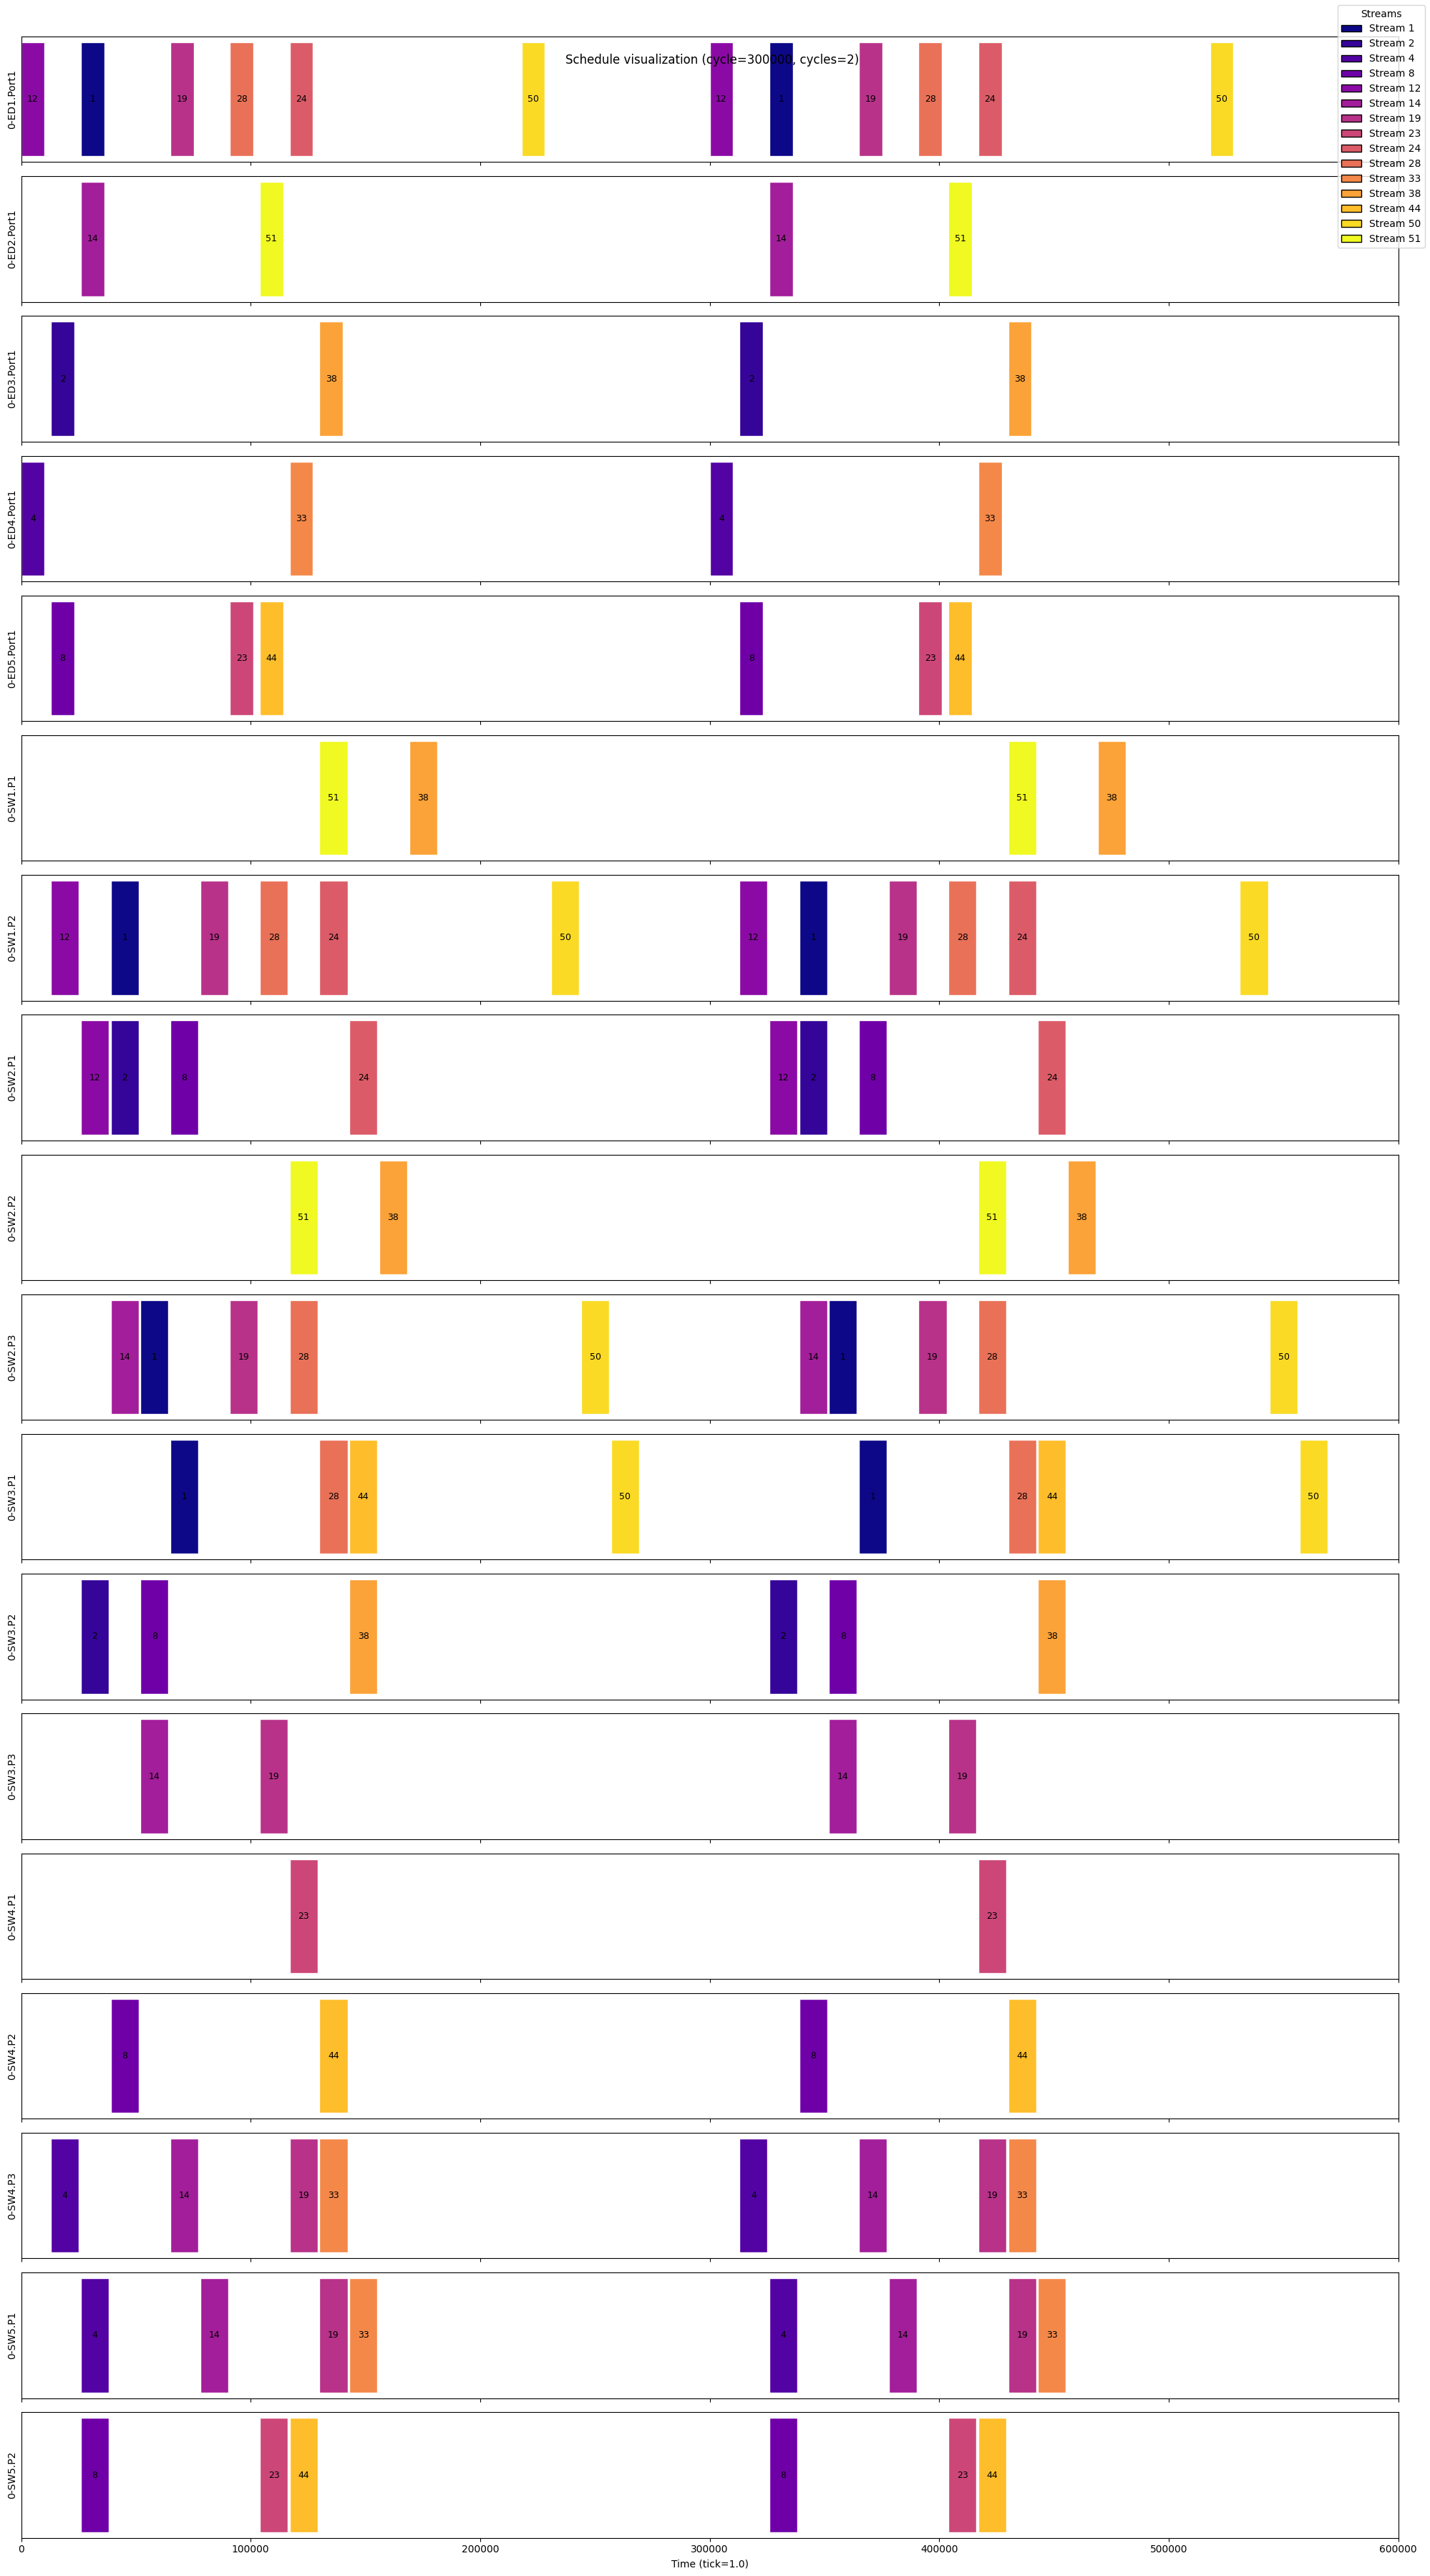

(<Figure size 2000x3600 with 18 Axes>,
 array([<Axes: ylabel='0-ED1.Port1'>, <Axes: ylabel='0-ED2.Port1'>,
        <Axes: ylabel='0-ED3.Port1'>, <Axes: ylabel='0-ED4.Port1'>,
        <Axes: ylabel='0-ED5.Port1'>, <Axes: ylabel='0-SW1.P1'>,
        <Axes: ylabel='0-SW1.P2'>, <Axes: ylabel='0-SW2.P1'>,
        <Axes: ylabel='0-SW2.P2'>, <Axes: ylabel='0-SW2.P3'>,
        <Axes: ylabel='0-SW3.P1'>, <Axes: ylabel='0-SW3.P2'>,
        <Axes: ylabel='0-SW3.P3'>, <Axes: ylabel='0-SW4.P1'>,
        <Axes: ylabel='0-SW4.P2'>, <Axes: ylabel='0-SW4.P3'>,
        <Axes: ylabel='0-SW5.P1'>,
        <Axes: xlabel='Time (tick=1.0)', ylabel='0-SW5.P2'>], dtype=object))

In [4]:
instance.schedule.plot(cycles=2, label=True)

In [7]:
with problem.use_instance(instance):
    evaluator = TSNConstraintEvaluator(problem, check_routing=False, check_task_placement=False)
    compact = instance.schedule.to_compact_encoding(problem.n_ports, problem.n_streams)
    print(evaluator.per_stream_all_violations(compact))
print(instance.schedule.validate_conflicts())

[[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]]
[]


In [15]:
import math
import random
import copy
import numpy as np
def run_no_defrag(
    instance,
    problem,
    n_episodes=8000,
    arrivals_per_episode=400,
    lambda_arrival=1.0,
    mu_departure=0.2,
    dt=1.0,
    seed=42,
    ed_ed_settings=None,
):
    """
    No-defragmentation benchmark.

    - arrivals per step ~ Poisson(lambda_arrival)
    - departures per active stream ~ exponential with per-step probability:
          p_dep = 1 - exp(-mu_departure * dt)
    - episode ends when total arrival requests reaches arrivals_per_episode
    """
    rng_py = random.Random(seed)
    rng_np = np.random.default_rng(seed)

    sbr_values = []
    acceptance_values = []
    steps_per_episode_list = []

    base_instance = instance
    p_dep = 1.0 - math.exp(-mu_departure * dt)

    for ep in range(n_episodes):
        inst = copy.deepcopy(base_instance)
        sched = inst.schedule
        ng = build_network_generator_from_usecase(inst)

        relevant_ports = sorted({slot.port_id for slot in sched if slot.port_id is not None})
        port_intervals = {
            pid: sched._occupied_intervals_on_port(pid, sched.cycle_ns)
            for pid in relevant_ports
        }

        accepted = 0
        rejected = 0
        total_arrivals = 0
        step_count = 0

        while total_arrivals < arrivals_per_episode:
            step_count += 1

            # Departures
            active_stream_ids = sorted({
                slot.stream_id for slot in sched
                if slot.stream_id is not None
            })
            n_active = len(active_stream_ids)

            if n_active > 0:
                n_dep = int(rng_np.binomial(n_active, p_dep))
                if n_dep > 0:
                    sched.delete_streams(
                        n_remove=n_dep,
                        usecase=inst,
                        rng=rng_py,
                        port_intervals=port_intervals,
                    )

            # Arrivals
            sampled_arrivals = int(rng_np.poisson(lambda_arrival))
            remaining = arrivals_per_episode - total_arrivals
            n_arr = min(sampled_arrivals, remaining)

            for _ in range(n_arr):
                total_arrivals += 1

                raw_stream = generate_one_arrival_stream(
                    ng,
                    ed_ed_settings=ed_ed_settings,
                )
                if raw_stream is None:
                    rejected += 1
                    continue

                stream_id = len(inst.streams)
                stream = build_usecase_stream_from_request(
                    raw_stream,
                    stream_id,
                    inst,
                    k_paths=1,
                )
                if stream is None:
                    rejected += 1
                    continue

                result = sched.place_stream_first_fit(
                    stream=stream,
                    usecase=inst,
                    problem=problem,
                    port_intervals=port_intervals,
                )

                if result["accepted"]:
                    accepted += 1
                else:
                    rejected += 1

        sbr = rejected / total_arrivals if total_arrivals > 0 else 0.0
        acc = accepted / total_arrivals if total_arrivals > 0 else 0.0

        sbr_values.append(sbr)
        acceptance_values.append(acc)
        steps_per_episode_list.append(step_count)

        if ep % 1 == 0:
            print(
                f"Episode {ep}: steps={step_count}, arrivals={total_arrivals}, "
                f"accepted={accepted}, rejected={rejected}, SBR={sbr:.4f}"
            )

    return (
        np.array(sbr_values),
        np.array(acceptance_values),
        np.array(steps_per_episode_list),
    )

In [16]:
def run_of_ff(
    instance,
    problem,
    p=5,
    n=5,
    n_episodes=8000,
    arrivals_per_episode=400,
    lambda_arrival=1.0,
    mu_departure=0.2,
    dt=1.0,
    seed=42,
    ed_ed_settings=None,
):
    """
    OF-FF(p,n) benchmark.

    Every p arrival requests:
    - select the n oldest active streams
    - try to reallocate each one stream-by-stream, hop-by-hop
    - if a stream cannot be reallocated, keep its old placement
    """
    rng_py = random.Random(seed)
    rng_np = np.random.default_rng(seed)

    sbr_values = []
    acceptance_values = []
    steps_per_episode_list = []

    base_instance = instance
    p_dep = 1.0 - math.exp(-mu_departure * dt)

    for ep in range(n_episodes):
        inst = copy.deepcopy(base_instance)
        sched = inst.schedule
        ng = build_network_generator_from_usecase(inst)

        relevant_ports = sorted({slot.port_id for slot in sched if slot.port_id is not None})
        port_intervals = {
            pid: sched._occupied_intervals_on_port(pid, sched.cycle_ns)
            for pid in relevant_ports
        }

        # smaller = older
        stream_age_key = {}
        for sid, stream in enumerate(inst.streams):
            offset = stream.get("offset", 10**9)
            stream_age_key[sid] = (0, offset)

        accepted = 0
        rejected = 0
        total_arrivals = 0
        step_count = 0

        while total_arrivals < arrivals_per_episode:
            step_count += 1

            # Departures
            active_stream_ids = sorted({
                slot.stream_id for slot in sched
                if slot.stream_id is not None
            })
            n_active = len(active_stream_ids)

            if n_active > 0:
                n_dep = int(rng_np.binomial(n_active, p_dep))
                if n_dep > 0:
                    sched.delete_streams(
                        n_remove=n_dep,
                        usecase=inst,
                        rng=rng_py,
                        port_intervals=port_intervals,
                    )

            # Arrivals
            sampled_arrivals = int(rng_np.poisson(lambda_arrival))
            remaining = arrivals_per_episode - total_arrivals
            n_arr = min(sampled_arrivals, remaining)

            for _ in range(n_arr):
                total_arrivals += 1

                raw_stream = generate_one_arrival_stream(
                    ng,
                    ed_ed_settings=ed_ed_settings,
                )
                if raw_stream is None:
                    rejected += 1
                    continue

                stream_id = len(inst.streams)
                stream = build_usecase_stream_from_request(
                    raw_stream,
                    stream_id,
                    inst,
                    k_paths=1,
                )
                if stream is None:
                    rejected += 1
                    continue

                result = sched.place_stream_first_fit(
                    stream=stream,
                    usecase=inst,
                    problem=problem,
                    port_intervals=port_intervals,
                )

                if result["accepted"]:
                    accepted += 1
                    new_sid = result["accepted"][-1]
                    stream_age_key[new_sid] = (1, total_arrivals)
                else:
                    rejected += 1

                # Trigger OF-FF every p arrivals
                sched.oldest_first_first_fit_defrag(
                    usecase=inst,
                    problem=problem,
                    p=p,
                    n=n,
                    arrival_counter=total_arrivals,
                    stream_age_key=stream_age_key,
                    port_intervals=port_intervals,
                )

        sbr = rejected / total_arrivals if total_arrivals > 0 else 0.0
        acc = accepted / total_arrivals if total_arrivals > 0 else 0.0

        sbr_values.append(sbr)
        acceptance_values.append(acc)
        steps_per_episode_list.append(step_count)

        if ep % 1 == 0:
            print(
                f"Episode {ep}: steps={step_count}, arrivals={total_arrivals}, "
                f"accepted={accepted}, rejected={rejected}, SBR={sbr:.4f}"
            )

    return (
        np.array(sbr_values),
        np.array(acceptance_values),
        np.array(steps_per_episode_list),
    )

In [20]:
import os
import numpy as np

from stable_baselines3 import DQN
from tsn_scheduling_problem import TSNScheduling
from env import TSNCandidatePathEnv


def run_drl_defrag(
    model_path,
    instance,
    problem,
    n_episodes=5,
    decision_points_per_episode=100,
    lambda_arrival=0.625,
    mu_departure=1.0,
    dt=1.0,
    seed=42,
    max_candidates=5,
    max_steps=500,
    max_hops=None,
    init_from_usecase_schedule=True,
    include_current_offset_candidate=True,
    beam_width=None,
    defrag_cycle_penalty=0.3,
    reallocation_penalty=0.05,
    top_k_oldest_random=10,   
    deterministic=True,
):
    """
    Evaluate trained DRL defrag policy episode by episode.

    Returns
    -------
    (sbr_values, acceptance_values, steps_per_episode)
        each is a numpy array of length n_episodes
    """

    if not os.path.exists(model_path):
        raise FileNotFoundError(f"Model not found: {model_path}")

    sbr_values = []
    acceptance_values = []
    steps_per_episode_list = []

    for ep in range(n_episodes):
        ep_seed = seed + ep

        # build a fresh env each episode, like your other benchmark functions
        env_kwargs = dict(
            problem=problem,
            usecase=instance,
            max_candidates=max_candidates,
            max_steps=max_steps,
            max_hops=max_hops,
            init_from_usecase_schedule=init_from_usecase_schedule,
            include_current_offset_candidate=include_current_offset_candidate,
            beam_width=beam_width,
            defrag_cycle_penalty=defrag_cycle_penalty,
            reallocation_penalty=reallocation_penalty,
            lambda_arrival=lambda_arrival,
            mu_departure=mu_departure,
            dt=dt,
            decision_points_per_episode=decision_points_per_episode,
            seed=ep_seed,
        )

        # only pass this if your env actually has it
        try:
            env = TSNCandidatePathEnv(
                **env_kwargs,
                top_k_oldest_random=top_k_oldest_random,
            )
        except TypeError:
            env = TSNCandidatePathEnv(**env_kwargs)

        model = DQN.load(model_path, env=env)

        obs, info = env.reset(seed=ep_seed)
        terminated = False
        truncated = False
        step_count = 0
        final_info = {}

        while not (terminated or truncated):
            action, _ = model.predict(obs, deterministic=deterministic)
            obs, reward, terminated, truncated, info = env.step(action)
            step_count += 1
            final_info = info

        # terminal info should already contain these; fallback computed directly if needed
        total_arrivals = final_info.get("episode_arrivals", getattr(env, "total_requests", 0))
        rejections = final_info.get("episode_rejections", getattr(env, "blocked_requests", 0))
        accepted = total_arrivals - rejections

        sbr = final_info.get(
            "episode_sbr",
            (rejections / total_arrivals) if total_arrivals > 0 else 0.0
        )
        acc = final_info.get(
            "episode_acceptance",
            (accepted / total_arrivals) if total_arrivals > 0 else 0.0
        )

        sbr_values.append(float(sbr))
        acceptance_values.append(float(acc))
        steps_per_episode_list.append(int(step_count))

        print(
            f"Episode {ep}: steps={step_count}, "
            f"decision_points={final_info.get('episode_decision_points', 'NA')}, "
            f"arrivals={total_arrivals}, accepted={accepted}, rejected={rejections}, "
            f"SBR={sbr:.4f}"
        )

        env.close()

    return (
        np.array(sbr_values, dtype=float),
        np.array(acceptance_values, dtype=float),
        np.array(steps_per_episode_list, dtype=int),
    )


In [18]:
import matplotlib.pyplot as plt
import numpy as np

def plot_multiple_sbr_curves(curves, smooth_window=None):
    """
    curves: dict like
    {
        "No-Defrag": sbr_values,
        "Heuristic-A": other_values,
        ...
    }
    """

    styles = [
        {"color": "red", "marker": "x", "linestyle": "-", "markersize": 4},
        {"color": "tab:blue", "marker": "o", "linestyle": "--", "markersize": 4},
        {"color": "tab:green", "marker": "s", "linestyle": "-.", "markersize": 4},
        {"color": "tab:purple", "marker": "+", "linestyle": "-", "markersize": 6},
        {"color": "tab:brown", "marker": "v", "linestyle": "--", "markersize": 4},
        {"color": "orange", "marker": "d", "linestyle": "-", "markersize": 4},
    ]

    plt.figure(figsize=(10, 5))

    for i, (label, values) in enumerate(curves.items()):
        y = np.asarray(values, dtype=float)
        x = np.arange(len(y))

        if smooth_window is not None and smooth_window > 1:
            kernel = np.ones(smooth_window) / smooth_window
            y = np.convolve(y, kernel, mode="same")

        style = styles[i % len(styles)]

        plt.plot(
            x, y,
            label=label,
            linewidth=1.2,
            **style
        )

    plt.xlabel("Episode", fontsize=12)
    plt.ylabel("Service Blocking Ratio (SBR)", fontsize=12)
    
    n = len(y)
    plt.xlim(0, n - 1)
    plt.margins(x=0)

    ticks = list(range(0, n, 1))
    if (n - 1) not in ticks:
        ticks.append(n - 1)

    # Replace last tick label with n instead of n-1
    labels = [str(t) for t in ticks]
    labels[-1] = str(n)

    plt.xticks(ticks, labels)
    #plt.grid(True, alpha=0.4)
    plt.legend()
    plt.tight_layout()
    plt.show()

In [ ]:
'''sbr_values = run_no_defrag(
    instance=instance,
    problem=problem,
    n_episodes=10,
    arrivals_per_episode=100,
    lambda_arrival=0.625,
    mu_departure=1,
)'''

'''sbr_values_of_ff = run_of_ff(
    instance=instance,
     problem=problem,
     p=15,
     n=1,
     n_episodes=100,
     arrivals_per_episode=100,
      lambda_arrival=1,
     mu_departure=1.2,
)'''

sbr_values_drl = run_drl_defrag(
    model_path="run_05/best_model.zip",
    instance=instance,
    problem=problem,
    n_episodes=100,
    decision_points_per_episode=100,
    lambda_arrival=0.1,
    mu_departure=0.02,
    dt=1.0,
    seed=42,
    max_candidates=5,
    max_steps=500,
    defrag_cycle_penalty=0.3,
    reallocation_penalty=0.05,
    deterministic=True,
)

Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.


AttributeError: 'Schedule' object has no attribute '_occupied_intervals_on_port'

In [29]:
print(sbr_values[0])

[0.3  0.17 0.36 0.28 0.3  0.26 0.21 0.27 0.24 0.24 0.27 0.24 0.2  0.27
 0.22 0.23 0.29 0.24 0.25 0.28 0.27 0.26 0.19 0.24 0.26 0.24 0.14 0.25
 0.24 0.22 0.17 0.29 0.24 0.24 0.22 0.2  0.3  0.21 0.24 0.25]


In [16]:
plot_multiple_sbr_curves(
    {"No-Defrag": sbr_values[0],
    "OF-FF(20,3)": sbr_values_of_ff[0],
    "Defrag": sbr_values_drl[0],
    },
    smooth_window=2)

NameError: name 'sbr_values_of_ff' is not defined

In [ ]:
import numpy as np
from tsn_scheduling_problem import TSNScheduling
from env import TSNCandidatePathEnv

problem = TSNScheduling("uc_config.cfg")
instance = problem.import_scheduling_usecase("banana.json")

env = TSNCandidatePathEnv(
    problem=problem,
    usecase=instance,
    max_candidates=5,
    max_steps=500,
    lambda_arrival=1.0,
    mu_departure=0.2,
    dt=1.0,
    decision_points_per_episode=30,
    ed_ed_settings=None,
    seed=42,
)

obs, _ = env.reset()

counts = []
for k in range(15):
    counts.append(len(env.current_candidates))
    print(
        f"dp={k+1}, focus={env.focus.stream_id}, "
        f"candidate_count={len(env.current_candidates)}, "
        f"mask={obs['candidate_mask'].tolist()}"
    )
    obs, reward, terminated, truncated, info = env.step(0)
    if terminated or truncated:
        break

print("candidate counts:", counts)
print("states with fewer than 5 candidates:", sum(c < 5 for c in counts))

dp=1, focus=0, candidate_count=5, mask=[1, 1, 1, 1, 1, 1]
dp=2, focus=0, candidate_count=5, mask=[1, 1, 1, 1, 1, 1]
dp=3, focus=0, candidate_count=5, mask=[1, 1, 1, 1, 1, 1]
dp=4, focus=5, candidate_count=5, mask=[1, 1, 1, 1, 1, 1]
dp=5, focus=5, candidate_count=5, mask=[1, 1, 1, 1, 1, 1]
dp=6, focus=5, candidate_count=5, mask=[1, 1, 1, 1, 1, 1]
dp=7, focus=5, candidate_count=5, mask=[1, 1, 1, 1, 1, 1]
dp=8, focus=22, candidate_count=5, mask=[1, 1, 1, 1, 1, 1]
dp=9, focus=25, candidate_count=5, mask=[1, 1, 1, 1, 1, 1]
dp=10, focus=25, candidate_count=5, mask=[1, 1, 1, 1, 1, 1]
dp=11, focus=25, candidate_count=5, mask=[1, 1, 1, 1, 1, 1]
dp=12, focus=25, candidate_count=5, mask=[1, 1, 1, 1, 1, 1]


dp=13, focus=63, candidate_count=5, mask=[1, 1, 1, 1, 1, 1]
dp=14, focus=65, candidate_count=5, mask=[1, 1, 1, 1, 1, 1]
dp=15, focus=65, candidate_count=4, mask=[1, 1, 1, 1, 1, 0]
candidate counts: [5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 4]
states with fewer than 5 candidates: 1
